In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [ ]:
iris = load_iris()
X = iris.data
y = iris.target

In [ ]:
print("Features (first 5 rows):\n", X[:5])
print("\nTargets (first 5 labels):\n", y[:5])
print("\nFeature Names:\n", iris.feature_names)
print("\nTarget Names:\n", iris.target_names)

Features (first 5 rows):
 [[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]]

Targets (first 5 labels):
 [0 0 0 0 0]

Feature Names:
 ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Target Names:
 ['setosa' 'versicolor' 'virginica']


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=0.2, random_state=42, stratify=y
        )

In [ ]:
print("Training Shape (X_train):", X_train.shape)
print("Testing Shape (X_test):", X_test.shape)

Training Shape (X_train): (120, 4)
Testing Shape (X_test): (30, 4)


In [ ]:
model = LogisticRegression(max_iter=200)
model.fit(X_train, y_train)

LogisticRegression(max_iter=200)

In [ ]:
y_pred = model.predict(X_test)
print("Predictions for first 10 test flowers:\n", y_pred[:10])
print("Actual labels for first 10 test flowers:\n", y_test[:10])

Predictions for first 10 test flowers:
 [0 2 1 1 0 1 0 0 2 1]
Actual labels for first 10 test flowers:
 [0 2 1 1 0 1 0 0 2 1]


In [ ]:
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy * 100:.2f}%")

Model Accuracy: 96.67%


In [ ]:
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, target_names=iris.target_names))

Confusion Matrix:
 [[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]

Classification Report:

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



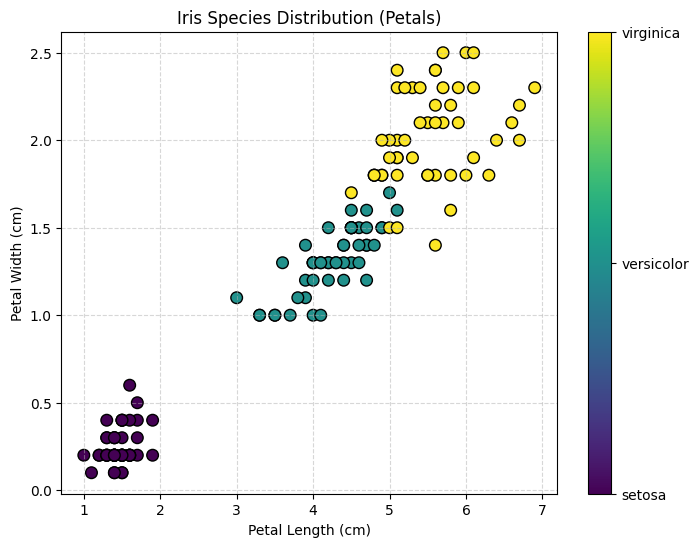

In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 2], X[:, 3], c=y, cmap='viridis', edgecolor='k', s=70)
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.title("Iris Species Distribution (Petals)")
plt.colorbar(ticks=[0, 1, 2], format=plt.FuncFormatter(lambda val, loc: iris.target_names[int(val)]))
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [ ]:
new_flower = [[5.1, 3.5, 1.4, 0.2]]
prediction = model.predict(new_flower)
predicted_species = iris.target_names[prediction][0]
print(f"The model predicts this new flower is: {predicted_species.upper()}")

The model predicts this new flower is: SETOSA
